# 04 — Association Rule Mining & Statistical Significance
**Analytics and Systems of Big Data Practice — Endsem Hackathon**
*IIITDM Kancheepuram*

## 1. Transaction Representation and Discretization
Inspect Representation C1 (22 contemporaneous tokens) and Representation C2 (24 predictive tokens).

**Database & Denominator Separation:**
- **Contemporaneous Mining:** Database C1 (N = 1,784, 22 tokens), minsup count = ceil(0.08 * 1784) = 143.
- **Predictive Rule Discovery:** Database C2 Train Only (N = 1,425, 24 tokens), minsup count = ceil(0.08 * 1425) = 114.
- **Predictive Test Evaluation:** Evaluated out-of-sample on Test period (N = 357).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path(os.getcwd()).resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from src.config import *
from IPython.display import Image, display

import json
with open(PROCESSED_DATA_DIR / 'transactions_predictive_S&P.json') as f:
    tx = json.load(f)
print('Total Predictive Transactions:', len(tx))
print('Sample Transaction:', tx[0])

Total Predictive Transactions: 1783
Sample Transaction: ['SameDay_Up', 'Mom5_Pos', 'Above_EMA50', 'CreditSpread_High', 'USD_Down', 'Gold_Down', 'Oil_Up', 'Tech_Leaders_Up', 'Europe_Up', 'NextDay_NotUp']


## 2. Integer Support FP-Growth & Rule Generation
Load mined frequent itemsets across both databases (143 for contemporaneous, 114 for predictive).

In [2]:
df_itemsets = pd.read_csv(TABLES_DIR / 'table_08_fp_growth_itemsets_S&P.csv')
print('Total Frequent Itemsets:', len(df_itemsets))
print('Breakdown by database:')
print(df_itemsets['database'].value_counts())
df_itemsets.head(10)

Total Frequent Itemsets: 2875
Breakdown by database:
database
Predictive_Train_1425        1652
Contemporaneous_Full_1784    1223
Name: count, dtype: int64


,support,itemsets,support_count,length,database,N_transactions,min_count_threshold
0,0.763453,"('Above_EMA50',)",1362,1,Contemporaneous_Full_1784,1784,143
1,0.599215,"('Mom5_Pos',)",1069,1,Contemporaneous_Full_1784,1784,143
2,0.545404,"('SameDay_Up',)",973,1,Contemporaneous_Full_1784,1784,143
3,0.539238,"('Above_EMA50', 'Mom5_Pos')",962,2,Contemporaneous_Full_1784,1784,143
4,0.507848,"('Oil_Up',)",906,1,Contemporaneous_Full_1784,1784,143
5,0.498318,"('USD_Up',)",889,1,Contemporaneous_Full_1784,1784,143
6,0.485426,"('Oil_Down',)",866,1,Contemporaneous_Full_1784,1784,143
7,0.484305,"('USD_Down',)",864,1,Contemporaneous_Full_1784,1784,143
8,0.478700,"('Gold_Up',)",854,1,Contemporaneous_Full_1784,1784,143
9,0.468610,"('Gold_Down',)",836,1,Contemporaneous_Full_1784,1784,143


## 3. Statistically Validated Association Rules & Out-of-Sample Test Evaluation
Inspect rules filtered by Conviction, Lift, and two-sided Fisher's Exact Test with Benjamini-Hochberg FDR correction.
For predictive rules, out-of-sample test support, confidence, lift, and conviction are evaluated on the 357 test rows.

In [3]:
df_rules = pd.read_csv(TABLES_DIR / 'table_10_validated_rules_S&P.csv')
print('Total Validated Rules:', len(df_rules))
print('Predictive Rules evaluated out-of-sample on test set:')
pred_val = df_rules[df_rules['rule_type'] == 'Predictive']
if len(pred_val) > 0:
    display(pred_val[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'test_support', 'test_confidence', 'test_lift', 'test_is_statistically_significant']].head(10))
else:
    display(df_rules.head(10))

Total Validated Rules: 5703
Predictive Rules evaluated out-of-sample on test set:


,antecedents,consequents,support,confidence,lift,test_support,test_confidence,test_lift,test_is_statistically_significant
5222,"('Above_EMA50', 'CreditSpread_Widening', 'USD_...","('NextDay_NotUp',)",0.085614,0.535088,1.171275,0.0728,0.4194,0.9416,False
5223,"('Above_EMA50', 'CreditSpread_Widening', 'Oil_...","('NextDay_NotUp',)",0.088421,0.531646,1.163740,0.0756,0.4154,0.9327,False
5224,"('Above_EMA50', 'Gold_Up', 'Mom5_Pos', 'USD_Do...","('NextDay_NotUp',)",0.081404,0.522523,1.143770,0.0868,0.5082,1.1410,False
5225,"('Above_EMA50', 'Gold_Down', 'TermSpread_Widen...","('NextDay_NotUp',)",0.086316,0.521186,1.140846,0.1064,0.4318,0.9696,False
5226,"('Above_EMA50', 'CreditSpread_Widening', 'Same...","('NextDay_NotUp',)",0.094737,0.519231,1.136565,0.0728,0.4062,0.9121,False
5227,"('Gold_Up', 'Mom5_Pos', 'USD_Down')","('NextDay_NotUp',)",0.091228,0.517928,1.133714,0.0896,0.5079,1.1405,False
5228,"('Above_EMA50', 'Mom5_Pos', 'Oil_Up', 'USD_Down')","('NextDay_NotUp',)",0.088421,0.516393,1.130354,0.0784,0.4375,0.9823,False
5229,"('Above_EMA50', 'CreditSpread_Widening', 'Mom5...","('NextDay_NotUp',)",0.101754,0.516014,1.129524,0.0980,0.4217,0.9468,False
5230,"('Europe_Up', 'Mom5_Pos', 'Oil_Up', 'SameDay_Up')","('NextDay_NotUp',)",0.081404,0.511013,1.118577,0.0784,0.4828,1.0839,False
5231,"('Above_EMA50', 'SameDay_Up', 'Tech_Leaders_Up')","('NextDay_NotUp',)",0.106667,0.510067,1.116506,0.1485,0.5146,1.1553,False


## 4. Association Rule Bubble Plot
Display Fig 11 (Support vs Confidence vs Lift with Conviction colormap).

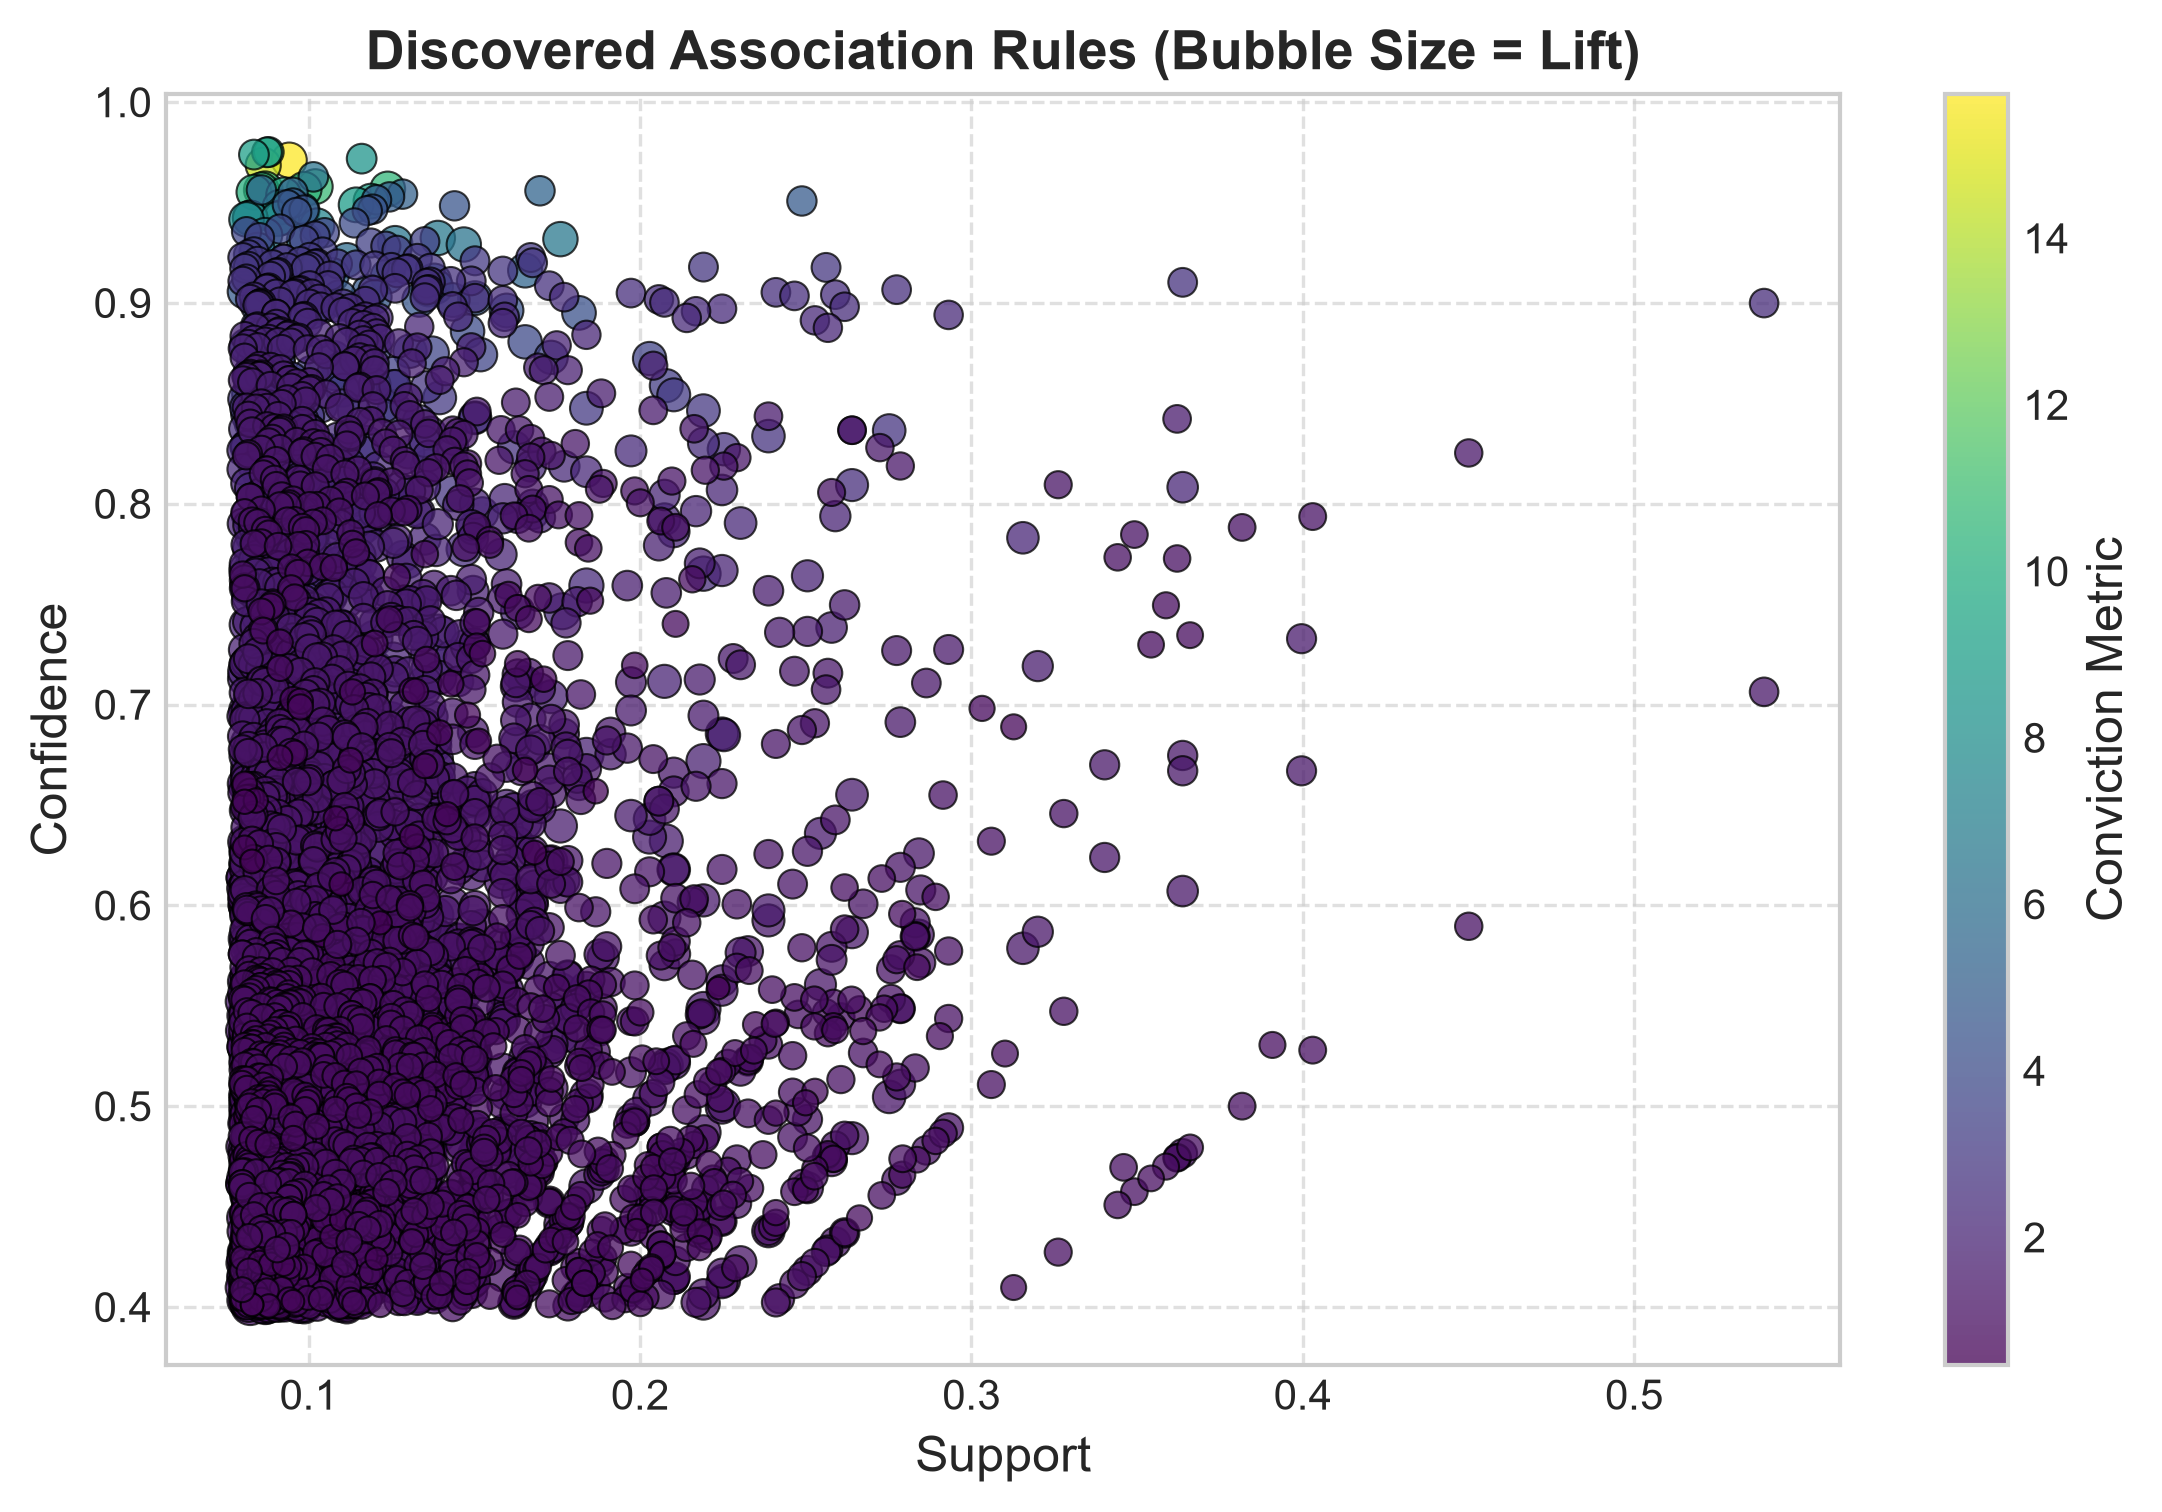

In [4]:
from IPython.display import Image, display
display(Image(filename=str(FIGURES_DIR / 'fig_11_association_rules_support_confidence_lift.png')))